## Analysis of Manual Topology Design and Configuration Times

This notebook analyzes the results of a survey conducted with participants regarding the average amount of time required to manually design network topologies and write CLI configurations. The goal is to highlight the time intensive nature of manual network setup to validate the efficiency benefits of our automated framework.

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the survey data
df = pd.read_csv('Time-Survey.csv')

# Rename columns for easier access
df.columns = [
    'Timestamp',
    'Design Time (Topology)',
    'Config Time (CLI)'
]

df.head()

,Timestamp,Design Time (Topology),Config Time (CLI)
0,2026/04/18 6:47:27 PM GMT+3,11–20 Minutes,41–60 Minutes
1,2026/04/18 6:47:43 PM GMT+3,1–10 Minutes,41–60 Minutes
2,2026/04/18 6:47:53 PM GMT+3,21–30 Minutes,More than 60 Minutes
3,2026/04/18 6:48:00 PM GMT+3,More than 30 Minutes,More than 60 Minutes
4,2026/04/18 6:48:09 PM GMT+3,1–10 Minutes,1–20 Minutes


### Distribution of Manual Topology Design Times

We first look at how long participants estimate it takes to manually design a network topology for a standard SME campus.

C:\Users\96653\AppData\Local\Temp\ipykernel_8052\278834682.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Design Time (Topology)', order=design_order, palette='Blues')


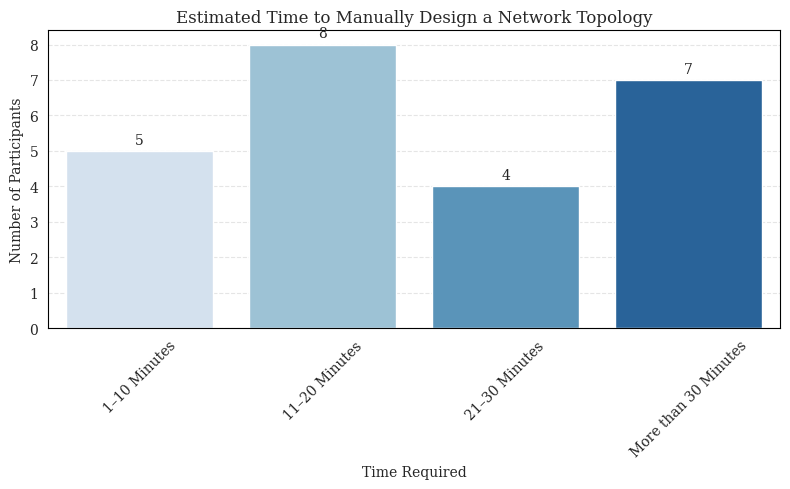

In [26]:
# Define the logical order for design times
design_order = [
    '1–10 Minutes',
    '11–20 Minutes',
    '21–30 Minutes',
    'More than 30 Minutes'
]

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Design Time (Topology)', order=design_order, palette='Blues')
plt.title('Estimated Time to Manually Design a Network Topology')
plt.xlabel('Time Required')
plt.ylabel('Number of Participants')
plt.xticks(rotation=45)

# Add data labels
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points')

plt.tight_layout()
plt.show()

### Distribution of Manual CLI Configuration Times

Next, we examine the estimated time to manually write the full Cisco IOS CLI configurations for the same campus.

C:\Users\96653\AppData\Local\Temp\ipykernel_8052\1957909770.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Config Time (CLI)', order=config_order, palette='Oranges')


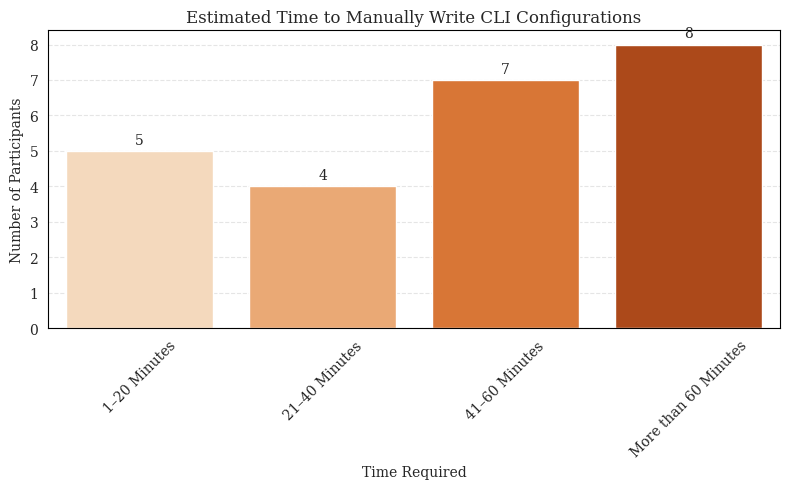

In [27]:
# Define the logical order for config times
config_order = [
    '1–20 Minutes',
    '21–40 Minutes',
    '41–60 Minutes',
    'More than 60 Minutes'
]

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Config Time (CLI)', order=config_order, palette='Oranges')
plt.title('Estimated Time to Manually Write CLI Configurations')
plt.xlabel('Time Required')
plt.ylabel('Number of Participants')
plt.xticks(rotation=45)

# Add data labels
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points')

plt.tight_layout()
plt.show()

### Cross-Analysis: Design vs Configuration Time

Let's visualize the relationship between design time and configuration time for individual participants using a heatmap.

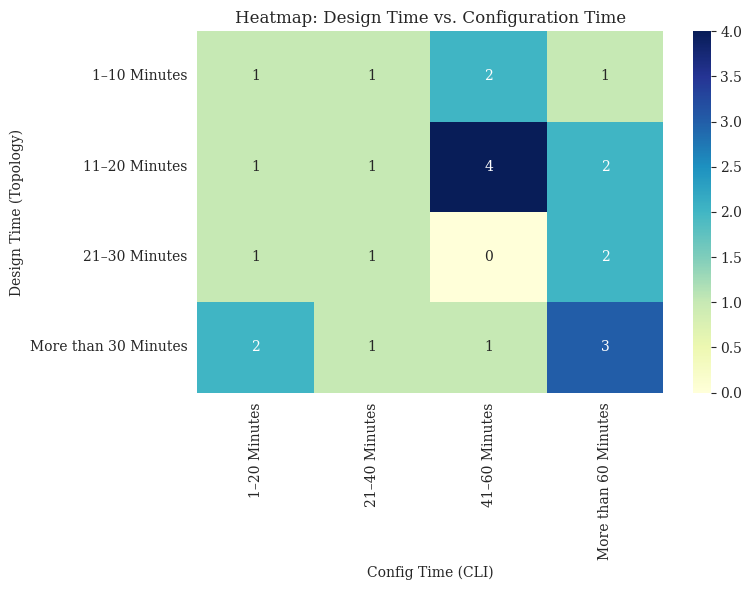

In [28]:
# Create a contingency table
cross_tab = pd.crosstab(df['Design Time (Topology)'], df['Config Time (CLI)'])

# Reorder rows and columns to match the time intervals
cross_tab = cross_tab.reindex(index=design_order, columns=config_order).fillna(0)

plt.figure(figsize=(8, 6))
sns.heatmap(cross_tab, annot=True, fmt="g", cmap="YlGnBu")
plt.title('Heatmap: Design Time vs. Configuration Time')
plt.xlabel('Config Time (CLI)')
plt.ylabel('Design Time (Topology)')
plt.tight_layout()
plt.show()

### Framework Automation Runtime

To explicitly demonstrate the time savings, let's analyze the runtime of our automated framework using the experimental scenario runs data.

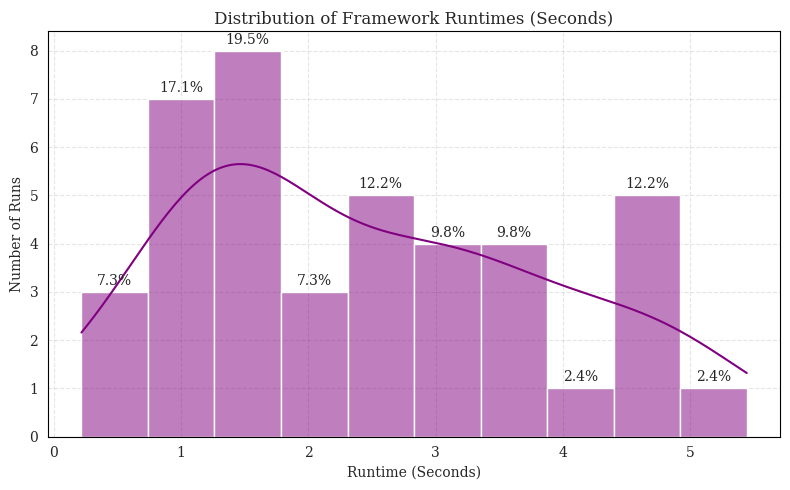

In [29]:
df_runs = pd.read_csv('scenario_runs.csv')

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_runs['Runtime (Seconds)'], bins=10, kde=True, color='purple')
plt.title('Distribution of Framework Runtimes (Seconds)')
plt.xlabel('Runtime (Seconds)')
plt.ylabel('Number of Runs')

# Add percentage labels
total = len(df_runs)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = f'{100 * height / total:.1f}%'
        ax.annotate(percentage, (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points')

plt.tight_layout()
plt.show()

### Conclusion

From the survey data, it is evident that a significant portion of participants require **more than 10 minutes** just to design the topology, and heavily slant upwards of **30+ minutes** for more complex logic. Similarly, manual configuration takes the majority of participants **upwards of 40-60+ minutes**.

In stark contrast, our automated framework functions complete its generations in the span of **less than 6 seconds (most taking ~1-4 seconds)** on average. Compared to the massive time sink involved in manual configuration, the framework offers a drastic reduction in operational time, empirically validating its core value proposition.